<a href="https://colab.research.google.com/github/nomulayogambika/ALCP/blob/main/Bus_Route_Passenger_Demand_Analysis(114)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



**Objective:** To analyze historical bus seat-booking data and identify yearly trends, monthly patterns, and variations in booked-seat demand using Python.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn and Google Colab.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Saving Dataset_D_Chennai_Hub_combined_data (1) to Dataset_D_Chennai_Hub_combined_data (1)
Dataset loaded successfully!
Dataset shape: (49, 4)


,serial,final_booked_seats,MONTH(TRAVEL_DATE),YEAR(TRAVEL_DATE)
0,1,10748,1,2011
1,2,8890,2,2011
2,3,8838,3,2011
3,4,13693,4,2011
4,5,20776,5,2011


In [3]:

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Shape:")
print(df.shape)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   serial              49 non-null     int64
 1   final_booked_seats  49 non-null     int64
 2   MONTH(TRAVEL_DATE)  49 non-null     int64
 3   YEAR(TRAVEL_DATE)   49 non-null     int64
dtypes: int64(4)
memory usage: 1.7 KB

Statistical Summary:


,serial,final_booked_seats,MONTH(TRAVEL_DATE),YEAR(TRAVEL_DATE)
count,49.00000,49.000000,49.000000,49.000000
mean,25.00000,28072.510204,6.387755,2012.551020
std,14.28869,12910.577222,3.540341,1.173691
min,1.00000,8838.000000,1.000000,2011.000000
25%,13.00000,20439.000000,3.000000,2012.000000
50%,25.00000,24915.000000,6.000000,2013.000000
75%,37.00000,31372.000000,9.000000,2014.000000
max,49.00000,75524.000000,12.000000,2015.000000



Missing Values:
serial                0
final_booked_seats    0
MONTH(TRAVEL_DATE)    0
YEAR(TRAVEL_DATE)     0
dtype: int64

Duplicate Records:
0

Dataset Shape:
(49, 4)


In [4]:

df['Month_Name'] = pd.to_datetime(
    df['MONTH(TRAVEL_DATE)'],
    format='%m'
).dt.month_name()
df['Travel_Date'] = pd.to_datetime(
    df['YEAR(TRAVEL_DATE)'].astype(str) + '-' +
    df['MONTH(TRAVEL_DATE)'].astype(str),
    format='%Y-%m'
)
df = df.sort_values('Travel_Date').reset_index(drop=True)
print("Data preparation completed!")
display(df.head(10))


Data preparation completed!


,serial,final_booked_seats,MONTH(TRAVEL_DATE),YEAR(TRAVEL_DATE),Month_Name,Travel_Date
0,1,10748,1,2011,January,2011-01-01
1,2,8890,2,2011,February,2011-02-01
2,3,8838,3,2011,March,2011-03-01
3,4,13693,4,2011,April,2011-04-01
4,5,20776,5,2011,May,2011-05-01
5,6,16954,6,2011,June,2011-06-01
6,7,16524,7,2011,July,2011-07-01
7,8,18980,8,2011,August,2011-08-01
8,9,17557,9,2011,September,2011-09-01
9,10,22030,10,2011,October,2011-10-01


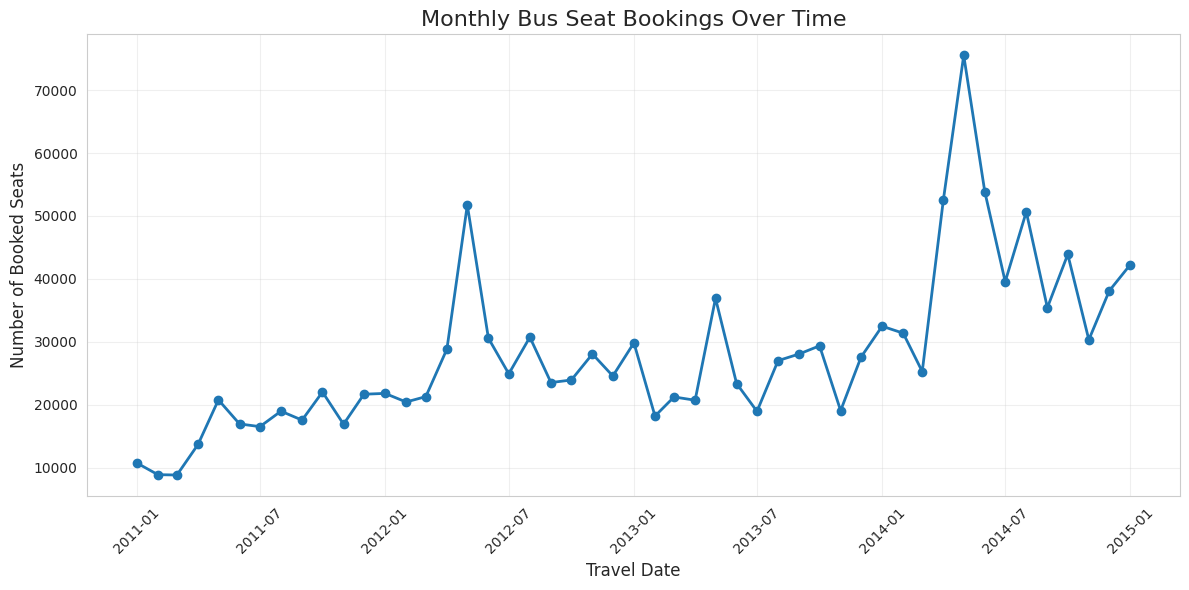

In [5]:

plt.figure(figsize=(12, 6))

plt.plot(
    df['Travel_Date'],
    df['final_booked_seats'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Bus Seat Bookings Over Time', fontsize=16)
plt.xlabel('Travel Date', fontsize=12)
plt.ylabel('Number of Booked Seats', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Interpretation

The time-series line chart shows the monthly variation in booked seats from 2011 to 2015. The values fluctuate over the study period, with some months recording higher bookings than others. The chart helps identify changes in booking demand over time and highlights months with unusually high or low values.


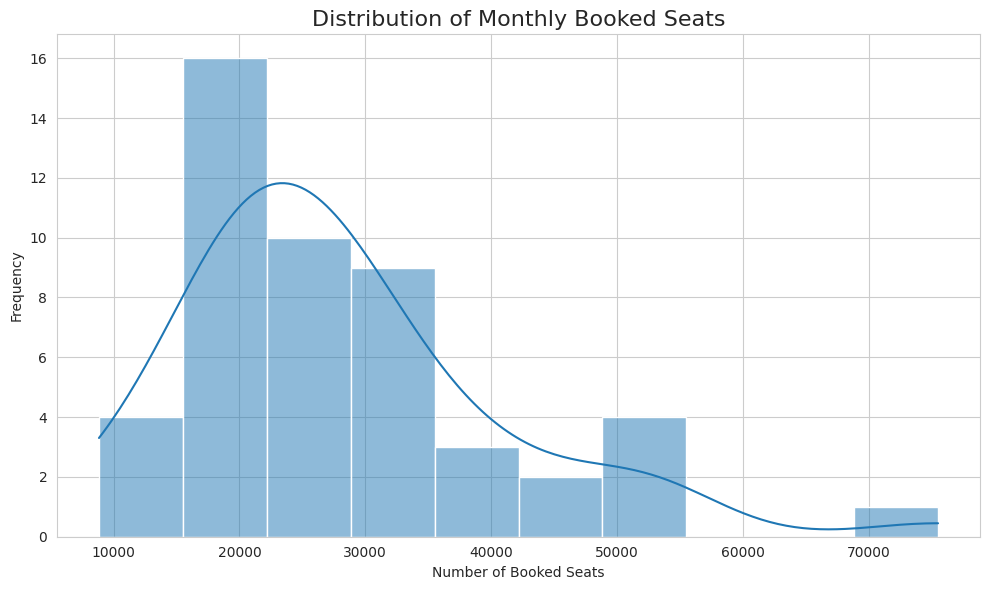

In [6]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='final_booked_seats',
    bins=10,
    kde=True
)

plt.title('Distribution of Monthly Booked Seats', fontsize=16)
plt.xlabel('Number of Booked Seats')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()



### Interpretation

The histogram displays the distribution of monthly booked-seat values. Most observations are concentrated in the lower and middle booking ranges, while a few months show considerably higher booking figures. The distribution indicates variation in booking levels across the study period.


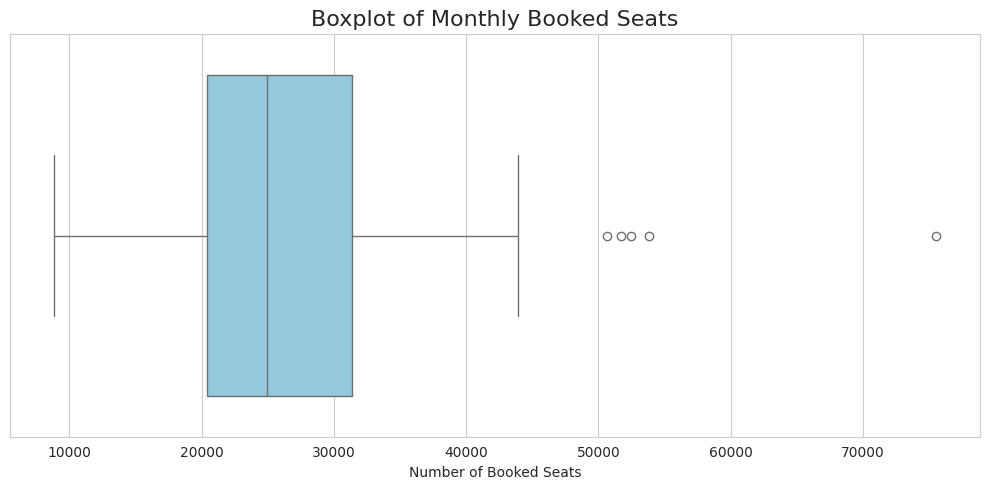

In [7]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df['final_booked_seats'],
    color='skyblue'
)

plt.title('Boxplot of Monthly Booked Seats', fontsize=16)
plt.xlabel('Number of Booked Seats')

plt.tight_layout()
plt.show()



### Interpretation

The boxplot illustrates the distribution and spread of monthly booked-seat values. It displays the median, interquartile range and potential outliers. Any points beyond the whiskers represent unusually high or low observations based on the boxplot rule. These observations are not necessarily errors and may reflect variations in booking demand.


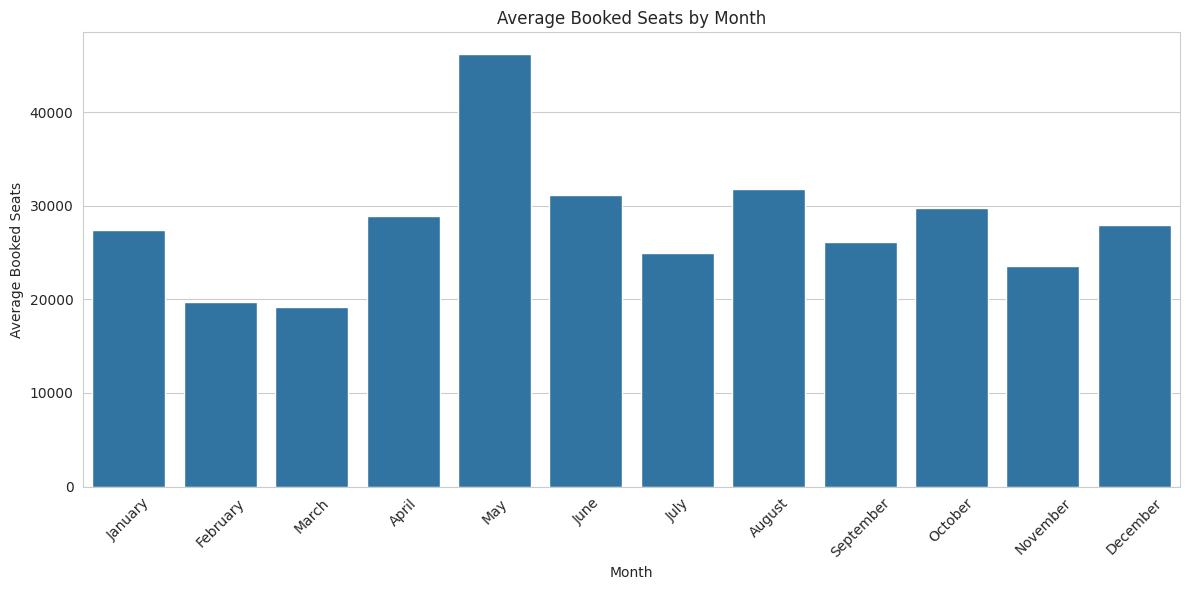

Monthly averages:


,final_booked_seats
Month_Name,
January,27428.80
February,19725.50
March,19162.25
April,28939.50
May,46237.00
June,31188.75
July,24987.00
August,31843.75
September,26145.25


In [8]:
monthly_avg = df.groupby('Month_Name')['final_booked_seats'].mean()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_avg = monthly_avg.reindex(month_order)

plt.figure(figsize=(12, 6))
sns.barplot(x=monthly_avg.index, y=monthly_avg.values)

plt.title('Average Booked Seats by Month')
plt.xlabel('Month')
plt.ylabel('Average Booked Seats')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Monthly averages:")
display(monthly_avg)


### Interpretation

The monthly average analysis shows that May recorded the highest average booked-seat figure of 46,237, while March recorded the lowest average of 19,162.25. This indicates that booking levels vary across months. These results can help identify months with relatively higher and lower booking demand.


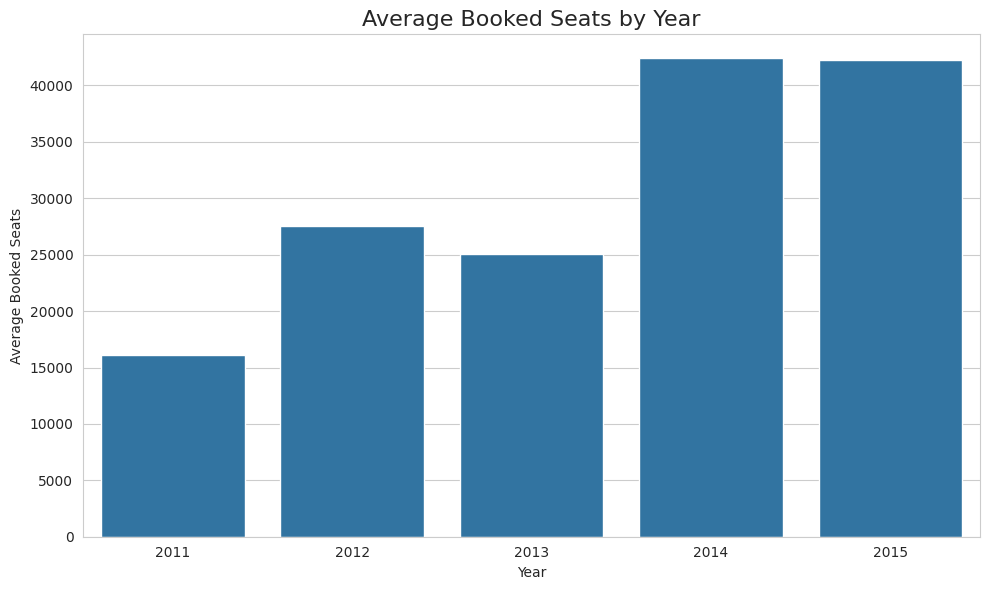

Yearly Average Booked Seats:


,final_booked_seats
YEAR(TRAVEL_DATE),
2011,16130.833333
2012,27537.916667
2013,25026.000000
2014,42412.166667
2015,42270.000000


In [9]:

yearly_avg = df.groupby('YEAR(TRAVEL_DATE)')['final_booked_seats'].mean()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=yearly_avg.index.astype(str),
    y=yearly_avg.values
)

plt.title('Average Booked Seats by Year', fontsize=16)
plt.xlabel('Year')
plt.ylabel('Average Booked Seats')

plt.tight_layout()
plt.show()

print("Yearly Average Booked Seats:")
display(yearly_avg)



### Interpretation

The yearly average analysis shows that 2014 recorded the highest average booked-seat figure, at approximately 42,412.17. The average increased from 2011 to 2012, decreased slightly in 2013, and increased considerably in 2014. The 2015 value is based on January alone, so it should not be directly compared with full-year averages.


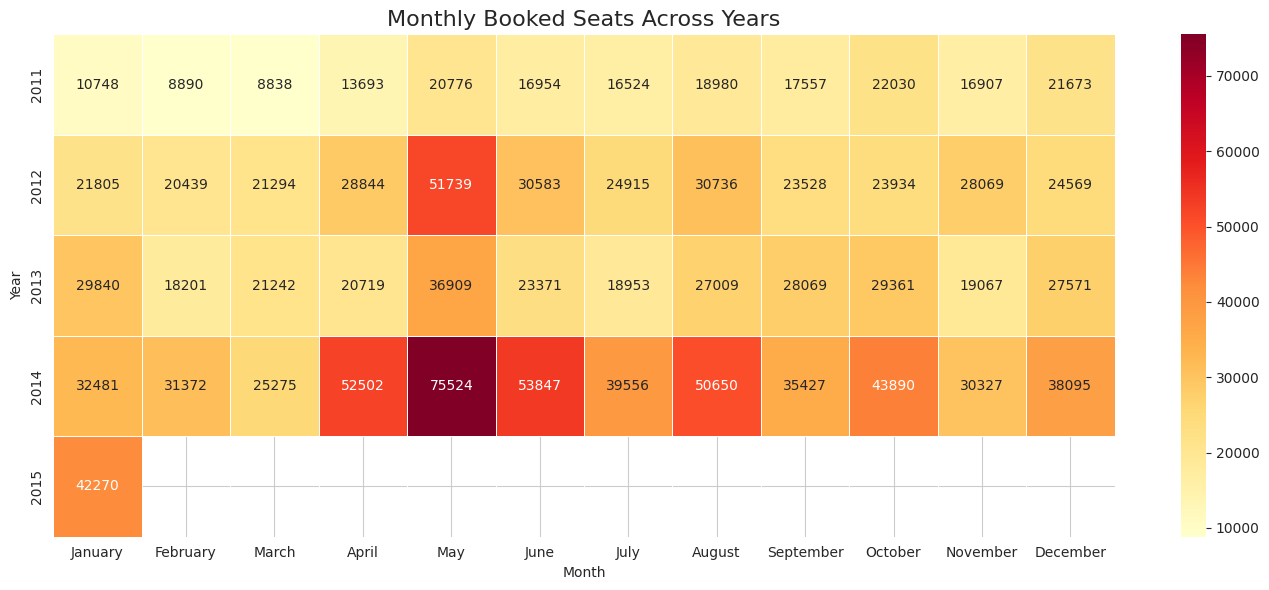

In [10]:


heatmap_data = df.pivot_table(
    index='YEAR(TRAVEL_DATE)',
    columns='Month_Name',
    values='final_booked_seats',
    aggfunc='mean'
)


month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

heatmap_data = heatmap_data.reindex(columns=month_order)


plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Monthly Booked Seats Across Years', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()



### Interpretation

The heatmap provides a comparison of monthly booked-seat figures across different years. It highlights variations in booking levels and makes it easier to identify months with relatively high or low values. Some months in 2014 show higher booking figures compared with earlier years. The 2015 row contains data only for January because the dataset ends in January 2015.


In [11]:


highest_record = df.loc[df['final_booked_seats'].idxmax()]


lowest_record = df.loc[df['final_booked_seats'].idxmin()]

print("Highest Booking Record:")
display(highest_record)

print("\nLowest Booking Record:")
display(lowest_record)


print("\nTop 5 Booking Records:")
top_5 = df.nlargest(5, 'final_booked_seats')
display(top_5[['Travel_Date', 'final_booked_seats']])


Highest Booking Record:


,40
serial,41
final_booked_seats,75524
MONTH(TRAVEL_DATE),5
YEAR(TRAVEL_DATE),2014
Month_Name,May
Travel_Date,2014-05-01 00:00:00



Lowest Booking Record:


,2
serial,3
final_booked_seats,8838
MONTH(TRAVEL_DATE),3
YEAR(TRAVEL_DATE),2011
Month_Name,March
Travel_Date,2011-03-01 00:00:00



Top 5 Booking Records:


,Travel_Date,final_booked_seats
40,2014-05-01,75524
41,2014-06-01,53847
39,2014-04-01,52502
16,2012-05-01,51739
43,2014-08-01,50650



### Interpretation

The highest booked-seat figure was 75,524, recorded in May 2014, while the lowest was 8,838, recorded in March 2011. The top five records include several months from 2014, indicating that some of the highest booking observations occurred during that year. These values show considerable variation in monthly booked-seat figures.


Correlation Matrix:


,final_booked_seats,YEAR(TRAVEL_DATE),MONTH(TRAVEL_DATE)
final_booked_seats,1.000000,0.678476,0.048990
YEAR(TRAVEL_DATE),0.678476,1.000000,-0.067532
MONTH(TRAVEL_DATE),0.048990,-0.067532,1.000000


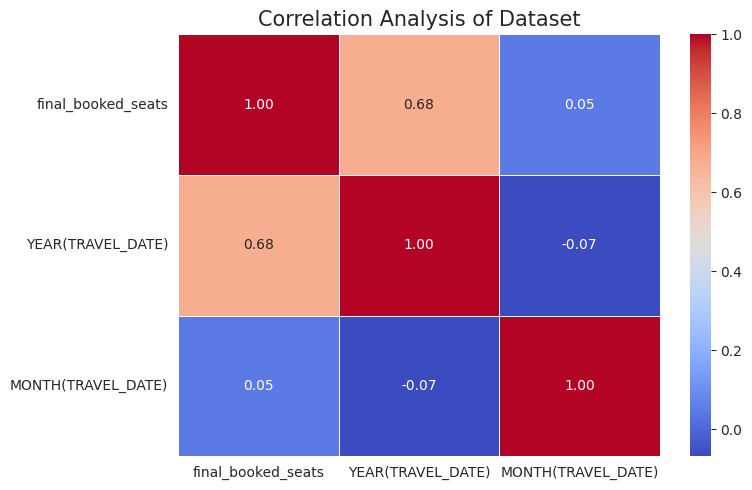

In [13]:



correlation_data = df[
    ['final_booked_seats',
     'YEAR(TRAVEL_DATE)',
     'MONTH(TRAVEL_DATE)']
]

correlation_matrix = correlation_data.corr()

print("Correlation Matrix:")
display(correlation_matrix)


plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Analysis of Dataset', fontsize=15)
plt.tight_layout()
plt.show()



### Interpretation

The correlation heatmap presents the linear relationships between booked seats, travel year and travel month. Correlation values help identify positive or negative associations between these variables. However, correlation does not establish causation. Since month is a cyclical variable and the dataset contains only 49 observations, these relationships should be interpreted with care.


Key Findings and Recommendations.

## 14. Key Findings

1. The dataset contains 49 monthly records covering January 2011 to January 2015.
2. The highest booked-seat value was 75,524 in May 2014.
3. The lowest booked-seat value was 8,838 in March 2011.
4. Among the complete years, 2014 recorded the highest average booked seats, approximately 42,412.
5. May had the highest monthly average of 46,237 booked seats.
6. March had the lowest monthly average of 19,162.25 booked seats.
7. The correlation analysis showed a moderate positive relationship between year and booked seats (0.68).
8. The data showed considerable variation in monthly booked-seat figures.

## 15. Recommendations

1. Bus operators can consider providing additional services during months with historically higher booking figures, particularly May.
2. Passenger demand should be monitored regularly to support better scheduling and resource planning.
3. During months with lower average bookings, operators can review service frequency and operational requirements.
4. Historical booking patterns can help operators prepare for periods of increased demand.
5. More recent data should be collected to understand current passenger booking trends.
6. Future analysis should include individual route details, passenger counts and actual travel information to provide more detailed insights.

## 16. Conclusion

This project analyzed historical bus seat-booking data using Python and Exploratory Data Analysis techniques. The dataset contained 49 monthly records from January 2011 to January 2015.

Pandas and NumPy were used for data handling and statistical analysis, while Matplotlib and Seaborn were used to create visualizations such as line charts, histograms, boxplots, bar charts and a heatmap.

The analysis identified changes in booked-seat figures over time, yearly and monthly booking patterns, and the highest and lowest booking records. The results showed that 2014 had the highest average among the complete years, while May had the highest monthly average.

Overall, this project demonstrates how data analysis and visualization can help understand historical bus seat-booking patterns and support planning decisions. The findings are based on the available booking data and do not necessarily represent the number of passengers who actually travelled.

## 17. Limitations

1. The dataset contains only 49 monthly records.
2. Individual bus route details are not available in the combined dataset.
3. The dataset records booked seats, not confirmed passenger travel.
4. The year 2015 contains only January data.
5. The dataset does not include factors such as ticket prices, holidays or weather conditions.

## 18. Future Scope

1. Include data from more years to study long-term trends.
2. Analyze individual bus routes when route-level data is available.
3. Compare booked seats with actual passenger travel data.
4. Study the effects of holidays, festivals and ticket prices on bookings.
5. Use predictive models to estimate future booking demand.

## 19. References

1. University of Strathclyde. Monthly Passenger Data on Certain Routes of an Intercity Bus System. Dataset source: https://pureportal.strath.ac.uk/en/datasets/monthly-passenger-data-on-certain-routes-of-an-intercity-bus-syst/

2. Pandas Documentation: https://pandas.pydata.org/docs/

3. NumPy Documentation: https://numpy.org/doc/

4. Matplotlib Documentation: https://matplotlib.org/stable/

5. Seaborn Documentation: https://seaborn.pydata.org/